Spark Standalone Benchmark

Spark applications with 1, 2, and 4 one-core workers, repeating each stage three times.




 Installing Spark and inspecting the available resources

In [ ]:
%pip -q install pyspark ucimlrepo seaborn

In [ ]:
import os, sys, subprocess, time, json, signal, urllib.request
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Logical CPUs:", os.cpu_count())
print("CPU quota (cgroup v2, if available):")
quota_file = Path('/sys/fs/cgroup/cpu.max')
print(quota_file.read_text().strip() if quota_file.exists() else 'Not available')
print("Java:")
subprocess.run(['java', '-version'], check=True)


Logical CPUs: 2
CPU quota (cgroup v2, if available):
max 100000
Java:


CompletedProcess(args=['java', '-version'], returncode=0)

Checking the Hardware and software environment
Record host RAM, Spark and Java versions before starting experiments.

In [ ]:
# Recording memory and software versions for reproducibility
import platform
import pyspark
import shutil

def total_ram_gb():
    with open('/proc/meminfo') as f:
        for line in f:
            if line.startswith('MemTotal:'):
                return int(line.split()[1]) / 1024**2
    return None

ram_gb = total_ram_gb()
print(f'Total host RAM: {ram_gb:.2f} GiB' if ram_gb is not None else 'RAM unavailable')
print('PySpark / Spark package version:', pyspark.__version__)
print('Python:', platform.python_version())
java_version = subprocess.run(['java', '-version'], capture_output=True, text=True)
print('Java version:\n' + (java_version.stderr or java_version.stdout).strip())
print('spark-submit version:')
spark_version = subprocess.run([str(Path(pyspark.__file__).resolve().parent / 'bin' / 'spark-submit'), '--version'], capture_output=True, text=True)
print((spark_version.stderr or spark_version.stdout)[-1800:])
metadata = {'total_ram_gib': ram_gb, 'spark_version': pyspark.__version__,
            'python_version': platform.python_version(),
            'java_version': (java_version.stderr or java_version.stdout).strip(),
            'spark_submit_version_output': (spark_version.stderr or spark_version.stdout).strip(),
            'logical_cpus': os.cpu_count()}
Path('/content/diabetes_benchmark_environment.json').write_text(json.dumps(metadata, indent=2))
print('Saved environment information to /content/diabetes_benchmark_environment.json')


Total host RAM: 12.67 GiB
PySpark / Spark package version: 4.0.4
Python: 3.13.16
Java version:
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
spark-submit version:
Welcome to
      ____              __
     / __/__  ___ _____/ /__
    _\ \/ _ \/ _ `/ __/  '_/
   /___/ .__/\_,_/_/ /_/\_\   version 4.0.4
      /_/
                        
Using Scala version 2.13.16, OpenJDK 64-Bit Server VM, 21.0.12.1
Branch HEAD
Compiled by user holden on 2026-07-12T04:41:54Z
Revision c7d67e3f5d4c9d88a480367b44fc54d26adf99ab
Url https://github.com/apache/spark
Type --help for more information.

Saved environment information to /content/diabetes_benchmark_environment.json


Downloading the UCI Diabetes dataset


In [ ]:
from ucimlrepo import fetch_ucirepo
cdc = fetch_ucirepo(id=891)
pdf = pd.concat([cdc.data.targets, cdc.data.features], axis=1)
DATA_FILE = '/content/cdc_diabetes_health_indicators.csv'
pdf.to_csv(DATA_FILE, index=False)
print('Rows, columns:', pdf.shape)
print('CSV:', DATA_FILE)


Rows, columns: (253680, 22)
CSV: /content/cdc_diabetes_health_indicators.csv


Starting one Spark Standalone master



In [ ]:
import pyspark
SPARK_HOME = Path(pyspark.__file__).resolve().parent
SPARK_CLASS = str(SPARK_HOME / 'bin' / 'spark-class')
SPARK_SUBMIT = str(SPARK_HOME / 'bin' / 'spark-submit')
LOG_DIR = Path('/content/spark_benchmark_logs')
LOG_DIR.mkdir(exist_ok=True)
MASTER_URL = 'spark://127.0.0.1:17077'
MASTER_API = 'http://127.0.0.1:18090/json/'

def launch(name, args):
    log = open(LOG_DIR / f'{name}.log', 'w')
    p = subprocess.Popen(args, stdout=log, stderr=subprocess.STDOUT,
                         start_new_session=True)
    log.close()
    time.sleep(2)
    if p.poll() is not None:
        raise RuntimeError(f'{name} exited. See {LOG_DIR / (name + ".log")}')
    return p

if 'master' not in globals() or master.poll() is not None:
    master = launch('master', [SPARK_CLASS,
        'org.apache.spark.deploy.master.Master',
        '--host', '127.0.0.1', '--port', '17077', '--webui-port', '18090'])

for attempt in range(20):
    try:
        with urllib.request.urlopen(MASTER_API, timeout=3) as response:
            master_info = json.load(response)
        break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError(f'Master UI not available; check {LOG_DIR / "master.log"}')
assert master_info.get('url', '').endswith(':17077'), f'Unexpected master: {master_info.get("url")}'
print('Master PID:', master.pid, '| Master URL:', MASTER_URL)
print('Master UI:', MASTER_API)


Master PID: 20395 | Master URL: spark://127.0.0.1:17077
Master UI: http://127.0.0.1:18090/json/


Assigning the Worker manager
Each worker is a separate Java process  with cores 1``memory 1g`.

In [ ]:
workers = [] if 'workers' not in globals() else workers

def stop_workers():
    global workers
    for p in workers:
        if p.poll() is None:
            os.killpg(p.pid, signal.SIGTERM)
    for p in workers:
        try:
            p.wait(timeout=15)
        except subprocess.TimeoutExpired:
            os.killpg(p.pid, signal.SIGKILL)
    workers = []
    time.sleep(2)

def start_workers(count):
    global workers
    stop_workers()
    if count not in (1, 2, 4):
        raise ValueError('Expected 1, 2, or 4 workers')
    for i in range(count):
        workers.append(launch(f'worker_{count}_{i+1}', [SPARK_CLASS,
            'org.apache.spark.deploy.worker.Worker',
            '--host', '127.0.0.1', '--port', '0', '--webui-port', '0',
            '--cores', '1', '--memory', '1g', MASTER_URL]))
    for attempt in range(45):
        try:
            with urllib.request.urlopen(MASTER_API, timeout=3) as response:
                info = json.load(response)
            alive = [w for w in info.get('workers', []) if w.get('state') == 'ALIVE']
            if len(alive) == count and sum(w.get('cores', 0) for w in alive) == count:
                print(f'Verified {count} live worker(s), {count} total core(s)')
                return
        except Exception:
            pass
        time.sleep(2)
    raise RuntimeError(f'Expected {count} live 1-core workers; inspect {LOG_DIR}')


 Creating the benchmark job from the Diabetes Risk Analysis and Prediction  notebook





Running a separate `local[1]` Spark application first, followed by the 1, 2 and 4-worker/executor standalone experiments.


In [ ]:
#Creating the benchmark script
from pathlib import Path
import subprocess
import json
import pandas as pd

BENCHMARK_SCRIPT = "/content/diabetes_benchmark_job.py"

script = """
import json
import sys
import time

from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.ml.stat import Correlation
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

num = int(sys.argv[1])
csv_path = sys.argv[2]
out_path = sys.argv[3]
is_local = sys.argv[4] == "local"

spark = SparkSession.builder.appName(f"CDC_Diabetes_{num}_Executors").getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext

def executor_count():
    # In client deploy-mode, driver is not counted in the executor IDs set.
    try:
        return sc._jsc.sc().getExecutorIds().size()
    except Exception:
        return 0

# Wait up to 120 seconds for the expected number of executors to register
for _ in range(120):
    if is_local or executor_count() == num:
        break
    time.sleep(1)

actual = 1 if is_local else executor_count()

if actual != num:
    raise RuntimeError(
        f"Expected {num} executors, got {actual}"
    )
"""

In [ ]:
#variables and preprocessing
script += """
# Variables from original diabetes notebook
analysis_variables = [
    'Diabetes_binary', 'HighBP', 'HighChol', 'BMI',
    'Smoker', 'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare',
    'NoDocbcCost', 'GenHlth', 'MentHlth',
    'PhysHlth', 'DiffWalk', 'Sex', 'Age',
    'Education', 'Income'
]

feature_columns = [
    'HighBP', 'HighChol', 'CholCheck', 'BMI',
    'Smoker', 'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare',
    'NoDocbcCost', 'GenHlth', 'MentHlth',
    'PhysHlth', 'DiffWalk', 'Sex', 'Age',
    'Education', 'Income'
]

risk_factors = [
    'HighBP', 'HighChol', 'Smoker',
    'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity'
]

# Preprocessing
def preprocessing():
    df = spark.read.csv(
        csv_path, header=True, inferSchema=True
    )

    missing_columns = set(
        feature_columns + ['Diabetes_binary']
    ) - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Missing columns: {sorted(missing_columns)}"
        )

    original_count = df.count()

    missing = df.select([
        F.count(F.when(F.col(c).isNull(), c)).alias(c)
        for c in df.columns
    ]).collect()[0]

    df = df.dropDuplicates()

    for c in df.columns:
        df = df.withColumn(c, F.col(c).cast('double'))

    clean_count = df.count()

    return df, original_count, clean_count
"""

In [ ]:
#statistical analysis
script += """
# Statistical analysis
def analysis(df):

    total = df.count()

    # Diabetes prevalence
    prevalence = (
        df.groupBy('Diabetes_binary')
        .count()
        .withColumn(
            'Percentage',
            F.round(F.col('count') / total * 100, 2)
        )
        .collect()
    )

    # Descriptive statistics
    description = df.select(
        'BMI', 'Age', 'GenHlth', 'MentHlth', 'PhysHlth'
    ).describe().collect()

    # BMI summary
    bmi = df.groupBy('Diabetes_binary').agg(
        F.count('*').alias('N'),
        F.round(F.mean('BMI'), 2).alias('Mean_BMI'),
        F.round(F.stddev('BMI'), 2).alias('SD_BMI')
    ).collect()

    # Age summary
    age = df.groupBy('Diabetes_binary').agg(
        F.round(F.mean('Age'), 2).alias('Mean_Age'),
        F.round(F.stddev('Age'), 2).alias('SD_Age')
    ).collect()

    # Risk factors
    for factor in risk_factors:
        df.groupBy(
            'Diabetes_binary', factor
        ).count().collect()

    # Pearson correlation
    assembler = VectorAssembler(
        inputCols=analysis_variables,
        outputCol='corr_features'
    )

    corr_df = assembler.transform(df)

    matrix = Correlation.corr(
        corr_df, 'corr_features', 'pearson'
    ).head()[0]

    return matrix
"""

In [ ]:
#machine learning pipeline
script += """
# Logistic regression pipeline
def make_pipeline():

    return Pipeline(stages=[
        VectorAssembler(
            inputCols=feature_columns,
            outputCol='unscaled_features'
        ),

        StandardScaler(
            inputCol='unscaled_features',
            outputCol='features',
            withStd=True,
            withMean=True
        ),

        LogisticRegression(
            featuresCol='features',
            labelCol='Diabetes_binary',
            maxIter=50,
            regParam=0.01
        )
    ])


# Prepare dataset
clean_df, original_count, clean_count = preprocessing()

train_df, test_df = clean_df.randomSplit(
    [0.80, 0.20], seed=42
)

train_df.cache()
test_df.cache()

train_count = train_df.count()
test_count = test_df.count()

print(
    f"Original: {original_count}, Clean: {clean_count}, "
    f"Train: {train_count}, Test: {test_count}",
    flush=True
)
"""

In [ ]:
#warmup and three tuntime measurements
script += """
# Benchmark operations
operations = [
    ('Preprocessing', preprocessing),
    ('Statistical Analysis', lambda: analysis(clean_df)),
    ('Machine Learning', lambda: make_pipeline().fit(train_df))
]

rows = []

# Warm-up (not timed)
for name, operation in operations:
    print(f"Warm-up: {name}", flush=True)
    operation()

print("Warm-up complete", flush=True)

# Three timed repetitions
for name, operation in operations:

    for repeat in range(1, 4):

        start = time.perf_counter()

        operation()

        seconds = time.perf_counter() - start

        rows.append({
            'Method': name,
            'Executors': num,
            'Cores_Per_Executor': 1,
            'Actual_Executors': actual,
            'Mode': 'local[1]' if is_local else 'standalone',
            'Repeat': repeat,
            'Time_Seconds': round(seconds, 4)
        })

        print(
            f"{name} | {num} executors | "
            f"Run {repeat}: {seconds:.3f}s",
            flush=True
        )
"""

In [ ]:
#model evaluation
import sys
from pathlib import Path

# Construct the entire script cleanly in one piece to guarantee correctness
full_script = """
import json
import sys
import time

from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.ml.stat import Correlation
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

num = int(sys.argv[1])
csv_path = sys.argv[2]
out_path = sys.argv[3]
is_local = sys.argv[4] == "local"

spark = SparkSession.builder.appName(f"CDC_Diabetes_{num}_Executors").getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext

def executor_count():
    # In client deploy-mode, driver is not counted in the executor IDs set.
    try:
        return sc._jsc.sc().getExecutorIds().size()
    except Exception:
        return 0

# Wait up to 120 seconds for the expected number of executors to register
for _ in range(120):
    if is_local or executor_count() == num:
        break
    time.sleep(1)

actual = 1 if is_local else executor_count()

if actual != num:
    raise RuntimeError(
        f"Expected {num} executors, got {actual}"
    )

# Variables from original diabetes notebook
analysis_variables = [
    'Diabetes_binary', 'HighBP', 'HighChol', 'BMI',
    'Smoker', 'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare',
    'NoDocbcCost', 'GenHlth', 'MentHlth',
    'PhysHlth', 'DiffWalk', 'Sex', 'Age',
    'Education', 'Income'
]

feature_columns = [
    'HighBP', 'HighChol', 'CholCheck', 'BMI',
    'Smoker', 'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare',
    'NoDocbcCost', 'GenHlth', 'MentHlth',
    'PhysHlth', 'DiffWalk', 'Sex', 'Age',
    'Education', 'Income'
]

risk_factors = [
    'HighBP', 'HighChol', 'Smoker',
    'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity'
]

# Preprocessing
def preprocessing():
    df = spark.read.csv(
        csv_path, header=True, inferSchema=True
    )

    missing_columns = set(
        feature_columns + ['Diabetes_binary']
    ) - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Missing columns: {sorted(missing_columns)}"
        )

    original_count = df.count()

    missing = df.select([
        F.count(F.when(F.col(c).isNull(), c)).alias(c)
        for c in df.columns
    ]).collect()[0]

    df = df.dropDuplicates()

    for c in df.columns:
        df = df.withColumn(c, F.col(c).cast('double'))

    clean_count = df.count()

    return df, original_count, clean_count

# Statistical analysis
def analysis(df):
    total = df.count()

    # Diabetes prevalence
    prevalence = (
        df.groupBy('Diabetes_binary')
        .count()
        .withColumn(
            'Percentage',
            F.round(F.col('count') / total * 100, 2)
        )
        .collect()
    )

    # Descriptive statistics
    description = df.select(
        'BMI', 'Age', 'GenHlth', 'MentHlth', 'PhysHlth'
    ).describe().collect()

    # BMI summary
    bmi = df.groupBy('Diabetes_binary').agg(
        F.count('*').alias('N'),
        F.round(F.mean('BMI'), 2).alias('Mean_BMI'),
        F.round(F.stddev('BMI'), 2).alias('SD_BMI')
    ).collect()

    # Age summary
    age = df.groupBy('Diabetes_binary').agg(
        F.round(F.mean('Age'), 2).alias('Mean_Age'),
        F.round(F.stddev('Age'), 2).alias('SD_Age')
    ).collect()

    # Risk factors
    for factor in risk_factors:
        df.groupBy(
            'Diabetes_binary', factor
        ).count().collect()

    # Pearson correlation
    assembler = VectorAssembler(
        inputCols=analysis_variables,
        outputCol='corr_features'
    )

    corr_df = assembler.transform(df)

    matrix = Correlation.corr(
        corr_df, 'corr_features', 'pearson'
    ).head()[0]

    return matrix

# Logistic regression pipeline
def make_pipeline():
    return Pipeline(stages=[
        VectorAssembler(
            inputCols=feature_columns,
            outputCol='unscaled_features'
        ),
        StandardScaler(
            inputCol='unscaled_features',
            outputCol='features',
            withStd=True,
            withMean=True
        ),
        LogisticRegression(
            featuresCol='features',
            labelCol='Diabetes_binary',
            maxIter=50,
            regParam=0.01
        )
    ])

# Prepare dataset
clean_df, original_count, clean_count = preprocessing()

train_df, test_df = clean_df.randomSplit(
    [0.80, 0.20], seed=42
)

train_df.cache()
test_df.cache()

train_count = train_df.count()
test_count = test_df.count()

print(
    f"Original: {original_count}, Clean: {clean_count}, "
    f"Train: {train_count}, Test: {test_count}",
    flush=True
)

# Benchmark operations
operations = [
    ('Preprocessing', preprocessing),
    ('Statistical Analysis', lambda: analysis(clean_df)),
    ('Machine Learning', lambda: make_pipeline().fit(train_df))
]

rows = []

# Warm-up (not timed)
for name, operation in operations:
    print(f"Warm-up: {name}", flush=True)
    operation()

print("Warm-up complete", flush=True)

# Three timed repetitions
for name, operation in operations:
    for repeat in range(1, 4):
        start = time.perf_counter()
        operation()
        seconds = time.perf_counter() - start
        rows.append({
            'Method': name,
            'Executors': num,
            'Cores_Per_Executor': 1,
            'Actual_Executors': actual,
            'Mode': 'local[1]' if is_local else 'standalone',
            'Repeat': repeat,
            'Time_Seconds': round(seconds, 4)
        })
        print(
            f"{name} | {num} executors | "
            f"Run {repeat}: {seconds:.3f}s",
            flush=True
        )

# Final test-set evaluation
model = make_pipeline().fit(train_df)
predictions = model.transform(test_df)

auc = BinaryClassificationEvaluator(
    labelCol='Diabetes_binary',
    metricName='areaUnderROC'
).evaluate(predictions)

evaluator = MulticlassClassificationEvaluator(
    labelCol='Diabetes_binary',
    predictionCol='prediction'
)

metrics = {'AUC': auc}

for metric in [
    'accuracy', 'weightedPrecision',
    'weightedRecall', 'f1'
]:
    metrics[metric] = evaluator.evaluate(
        predictions, {evaluator.metricName: metric}
    )

print("Test metrics:", metrics, flush=True)

# Save results
with open(out_path, 'w') as file:
    json.dump({
        'config': num,
        'mode': 'local[1]' if is_local else 'standalone',
        'actual_executors': actual,
        'original_rows': original_count,
        'clean_rows': clean_count,
        'train_rows': train_count,
        'test_rows': test_count,
        'timings': rows,
        'test_metrics': metrics
    }, file, indent=2)

spark.stop()
"""

# Create and overwrite the benchmark Python file cleanly
Path(BENCHMARK_SCRIPT).write_text(full_script)
compile(full_script, BENCHMARK_SCRIPT, "exec")



Overwrote benchmark script completely with the fixed code!


Running the experiments

In [ ]:
#checking the inputs
assert Path(DATA_FILE).is_file(), "Dataset not found"
assert Path(BENCHMARK_SCRIPT).is_file(), "Benchmark script not found"
assert master.poll() is None, "Spark master is not running"

print("All required files and Spark master are ready.")

All required files and Spark master are ready.


In [ ]:
#running local(1) baseline
# Stop standalone workers
stop_workers()

baseline_output = "/content/benchmark_local_1.json"

command = [
    SPARK_SUBMIT,
    "--master", "local[1]",
    "--conf", "spark.ui.enabled=false",
    "--conf", "spark.driver.memory=1g",
    "--conf", "spark.default.parallelism=4",
    "--conf", "spark.sql.shuffle.partitions=4",
    BENCHMARK_SCRIPT,
    "1", DATA_FILE, baseline_output, "local"
]

log_file = LOG_DIR / "job_local_1.log"

with open(log_file, "w") as log:
    result = subprocess.run(
        command,
        stdout=log,
        stderr=subprocess.STDOUT,
        timeout=2400
    )

print(log_file.read_text()[-1800:])

if result.returncode != 0:
    raise RuntimeError("Local baseline failed. Check the log.")

baseline_report = json.loads(Path(baseline_output).read_text())

baseline_timings = pd.DataFrame(baseline_report["timings"])

baseline_timings.to_csv(
    "/content/diabetes_benchmark_local_baseline.csv",
    index=False
)

display(baseline_timings)

asspath (userClassPathFirst = false): ''
26/10/30 20:26:31 INFO Executor: Created or updated repl class loader org.apache.spark.util.MutableURLClassLoader@3977a0c2 for default.
26/10/30 20:26:31 INFO Utils: Successfully started service 'org.apache.spark.network.netty.NettyBlockTransferService' on port 42663.
26/10/30 20:26:31 INFO NettyBlockTransferService: Server created on 09765b8d1aa6:42663
26/10/30 20:26:31 INFO BlockManager: Using org.apache.spark.storage.RandomBlockReplicationPolicy for block replication policy
26/10/30 20:26:31 INFO BlockManagerMaster: Registering BlockManager BlockManagerId(driver, 09765b8d1aa6, 42663, None)
26/10/30 20:26:31 INFO BlockManagerMasterEndpoint: Registering block manager 09765b8d1aa6:42663 with 434.4 MiB RAM, BlockManagerId(driver, 09765b8d1aa6, 42663, None)
26/10/30 20:26:31 INFO BlockManagerMaster: Registered BlockManager BlockManagerId(driver, 09765b8d1aa6, 42663, None)
26/10/30 20:26:31 INFO BlockManager: Initialized BlockManager: BlockManagerI

,Method,Executors,Cores_Per_Executor,Actual_Executors,Mode,Repeat,Time_Seconds
0,Preprocessing,1,1,1,local[1],1,3.6176
1,Preprocessing,1,1,1,local[1],2,3.2528
2,Preprocessing,1,1,1,local[1],3,3.3303
3,Statistical Analysis,1,1,1,local[1],1,17.7887
4,Statistical Analysis,1,1,1,local[1],2,16.2426
5,Statistical Analysis,1,1,1,local[1],3,15.2727
6,Machine Learning,1,1,1,local[1],1,4.8112
7,Machine Learning,1,1,1,local[1],2,4.7985
8,Machine Learning,1,1,1,local[1],3,5.1248


In [ ]:
#Running 1,2,4 executors
import subprocess

# Forcefully kill any residual Spark worker and master processes to ensure ports and slots are freed up
print("Cleaning up orphaned Spark JVM processes...")
subprocess.run("pkill -f org.apache.spark.deploy.worker.Worker", shell=True)
time.sleep(2)

all_timings = []
all_metrics = []

for count in [1, 2, 4]:

    print(f"\n===== {count} EXECUTOR(S) =====")

    start_workers(count)

    output = f"/content/benchmark_{count}_executors.json"

    command = [
        SPARK_SUBMIT,
        "--master", MASTER_URL,
        "--deploy-mode", "client",
        "--conf", f"spark.cores.max={count}",
        "--conf", "spark.executor.cores=1",
        "--conf", f"spark.executor.instances={count}",
        "--conf", "spark.dynamicAllocation.enabled=false",
        "--conf", "spark.executor.memory=1g",
        "--conf", "spark.executor.memoryOverhead=384m",
        "--conf", "spark.driver.memory=1g",
        "--conf", "spark.ui.enabled=false",
        "--conf", "spark.port.maxRetries=32",
        "--conf", "spark.default.parallelism=4",
        "--conf", "spark.sql.shuffle.partitions=4",
        BENCHMARK_SCRIPT,
        str(count), DATA_FILE, output, "standalone"
    ]

    log_file = LOG_DIR / f"job_{count}.log"

    with open(log_file, "w") as log:
        result = subprocess.run(
            command,
            stdout=log,
            stderr=subprocess.STDOUT,
            timeout=2400
        )

    print(log_file.read_text()[-2500:])

    if result.returncode != 0:
        raise RuntimeError(
            f"{count}-executor experiment failed. Check {log_file}"
        )

    report = json.loads(Path(output).read_text())

    if report["actual_executors"] != count:
        raise RuntimeError("Executor count mismatch")

    all_timings.extend(report["timings"])

    all_metrics.append({
        "Executors": count,
        **report["test_metrics"]
    })

# Stopping workers after experiments
stop_workers()

# Saving the results
timings = pd.DataFrame(all_timings)
model_metrics = pd.DataFrame(all_metrics)

timings.to_csv(
    "/content/diabetes_benchmark_raw.csv", index=False
)

model_metrics.to_csv(
    "/content/diabetes_benchmark_test_metrics.csv", index=False
)

print("Runtime Results")
display(timings)

print("Test Set Performance")
display(model_metrics.round(4))

Cleaning up orphaned Spark JVM processes...

===== 1 EXECUTOR(S) =====
Verified 1 live worker(s), 1 total core(s)
added: app-20261030204001-0004/0 on worker-20261030203954-127.0.0.1-43885 (127.0.0.1:43885) with 1 core(s)
26/10/30 20:40:01 INFO StandaloneSchedulerBackend: Granted executor ID app-20261030204001-0004/0 on hostPort 127.0.0.1:43885 with 1 core(s), 1024.0 MiB RAM
26/10/30 20:40:01 INFO Utils: Successfully started service 'org.apache.spark.network.netty.NettyBlockTransferService' on port 36469.
26/10/30 20:40:01 INFO NettyBlockTransferService: Server created on 09765b8d1aa6:36469
26/10/30 20:40:01 INFO BlockManager: Using org.apache.spark.storage.RandomBlockReplicationPolicy for block replication policy
26/10/30 20:40:01 INFO BlockManagerMaster: Registering BlockManager BlockManagerId(driver, 09765b8d1aa6, 36469, None)
26/10/30 20:40:01 INFO BlockManagerMasterEndpoint: Registering block manager 09765b8d1aa6:36469 with 434.4 MiB RAM, BlockManagerId(driver, 09765b8d1aa6, 36469,

,Method,Executors,Cores_Per_Executor,Actual_Executors,Mode,Repeat,Time_Seconds
0,Preprocessing,1,1,1,standalone,1,4.2109
1,Preprocessing,1,1,1,standalone,2,4.1227
2,Preprocessing,1,1,1,standalone,3,3.6864
3,Statistical Analysis,1,1,1,standalone,1,21.7498
4,Statistical Analysis,1,1,1,standalone,2,19.8666
5,Statistical Analysis,1,1,1,standalone,3,17.1746
6,Machine Learning,1,1,1,standalone,1,5.2718
7,Machine Learning,1,1,1,standalone,2,4.4871
8,Machine Learning,1,1,1,standalone,3,4.8462
9,Preprocessing,2,1,2,standalone,1,4.8523


Test Set Performance


,Executors,AUC,accuracy,weightedPrecision,weightedRecall,f1
0,1,0.8061,0.8487,0.8139,0.8487,0.8064
1,2,0.8061,0.8487,0.8139,0.8487,0.8064
2,4,0.8061,0.8487,0.8139,0.8487,0.8064


Calculating the mean runtime, standard deviation and speedup

In [ ]:
results = (timings.groupby(['Method','Executors'], as_index=False)
           .agg(Mean_Time=('Time_Seconds','mean'),
                SD_Time=('Time_Seconds','std')))
baselines = results[results['Executors'] == 1].set_index('Method')['Mean_Time']
results['Speedup'] = results.apply(
    lambda row: baselines[row['Method']] / row['Mean_Time'], axis=1)
results['Efficiency'] = results['Speedup'] / results['Executors']
results.to_csv('/content/diabetes_benchmark_summary.csv', index=False)
display(results.round(3))

# Compare all standalone settings with the local[1] baseline as well.
local_means = baseline_timings.groupby('Method')['Time_Seconds'].mean()
results['Local1_Mean_Time'] = results['Method'].map(local_means)
results['Speedup_vs_Local1'] = results['Local1_Mean_Time'] / results['Mean_Time']
results.to_csv('/content/diabetes_benchmark_summary.csv', index=False)
print('Standalone results compared with local[1] baseline:')
display(results.round(3))


,Method,Executors,Mean_Time,SD_Time,Speedup,Efficiency
0,Machine Learning,1,4.868,0.393,1.000,1.000
1,Machine Learning,2,5.653,0.565,0.861,0.431
2,Machine Learning,4,7.558,0.843,0.644,0.161
3,Preprocessing,1,4.007,0.281,1.000,1.000
4,Preprocessing,2,4.276,0.524,0.937,0.468
5,Preprocessing,4,5.259,0.776,0.762,0.190
6,Statistical Analysis,1,19.597,2.299,1.000,1.000
7,Statistical Analysis,2,19.848,3.072,0.987,0.494
8,Statistical Analysis,4,26.651,1.902,0.735,0.184


Standalone results compared with local[1] baseline:


,Method,Executors,Mean_Time,SD_Time,Speedup,Efficiency,Local1_Mean_Time,Speedup_vs_Local1
0,Machine Learning,1,4.868,0.393,1.000,1.000,4.912,1.009
1,Machine Learning,2,5.653,0.565,0.861,0.431,4.912,0.869
2,Machine Learning,4,7.558,0.843,0.644,0.161,4.912,0.650
3,Preprocessing,1,4.007,0.281,1.000,1.000,3.400,0.849
4,Preprocessing,2,4.276,0.524,0.937,0.468,3.400,0.795
5,Preprocessing,4,5.259,0.776,0.762,0.190,3.400,0.647
6,Statistical Analysis,1,19.597,2.299,1.000,1.000,16.435,0.839
7,Statistical Analysis,2,19.848,3.072,0.987,0.494,16.435,0.828
8,Statistical Analysis,4,26.651,1.902,0.735,0.184,16.435,0.617


Comparing average runtimes and speedup

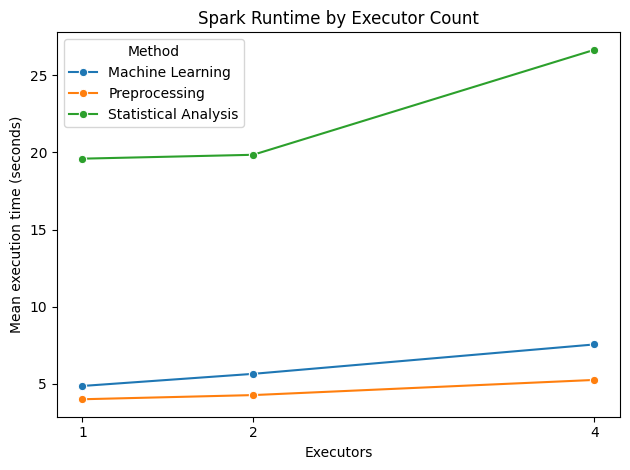

In [ ]:
sns.lineplot(data=results, x='Executors', y='Mean_Time',
             hue='Method', marker='o')
plt.xticks([1,2,4])
plt.ylabel('Mean execution time (seconds)')
plt.title('Spark Runtime by Executor Count')
plt.tight_layout()
plt.savefig('/content/benchmark_mean_runtime.png', dpi=200)
plt.show()


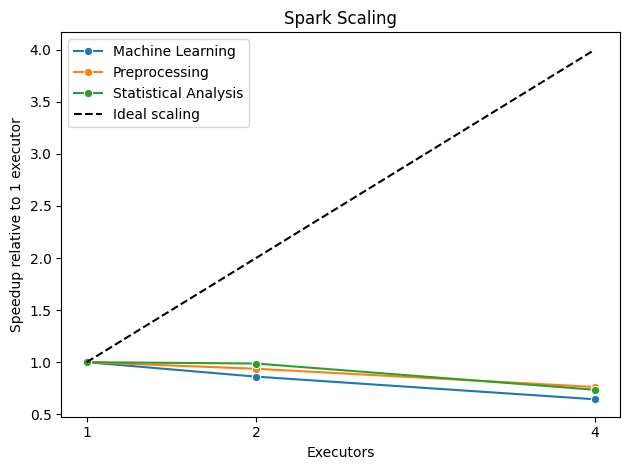

In [ ]:
sns.lineplot(data=results, x='Executors', y='Speedup',
             hue='Method', marker='o')
plt.plot([1,2,4], [1,2,4], '--', color='black', label='Ideal scaling')
plt.xticks([1,2,4])
plt.ylabel('Speedup relative to 1 executor')
plt.title('Spark Scaling')
plt.legend()
plt.tight_layout()
plt.savefig('/content/benchmark_speedup.png', dpi=200)
plt.show()


In [ ]:
stop_workers()
if master.poll() is None:
    os.killpg(master.pid, signal.SIGTERM)
print('Stopped Spark workers and master.')
print('Files: /content/diabetes_benchmark_raw.csv, /content/diabetes_benchmark_summary.csv')
